# 03 · Filter comparison
Does extra filtering help state detection? Signal-side filters (moving average, Kalman, median) are applied to current **before** detection; the minimum-duration filter is applied to the detected states **after** detection. Each is combined with A41 threshold, A42 GMM and A43 HMM. Run with `MACHINE = 4`, then `3`.

In [1]:
import sys, time
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "config.py").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
import config as C
from src import detection as D

MACHINE = 3                                  # 4, then 3
K = C.STATES[MACHINE]                        # number of physical states (from the histogram)
STATE = D.names(K)[0]
SPLIT = pd.Timestamp("2026-08-01")           # evaluation uses data from SPLIT onwards
ZOOM_DAY = "2026-09-08"                      # local date for the close-up plot
MA_W, MED_W, KF_QR, MIN_LEN = 3, 3, 0.1, 3   # 15 s window, 15 s window, Kalman Q/R, 15 s minimum run

df = pd.read_parquet(C.SILVER / "timeline.parquet", filters=[("machine", "==", MACHINE)]).reset_index(drop=True)
df["missing"] = ~df.has_data | df.I.isna()
df["day"] = df.t_local.dt.strftime("%Y-%m-%d")
df["excluded"] = df.day.isin(C.TEST_DAYS + C.ANOMALY_DAYS)
valid = (~df.missing & ~df.meter_off).to_numpy()
n_days = df.day[~df.missing].nunique()
test = ((df.t >= SPLIT) & ~df.missing & df.status.notna() & ~df.excluded).to_numpy()
yt = (df.status == "RUNNING").to_numpy()
I = df.I.to_numpy()
print(f"Patch {C.PATCH}, machine {MACHINE}: {len(df):,} slots, {n_days} days with data")

Patch patch1, machine 3: 2,183,058 slots, 127 days with data


## 1 · Signal-side filters
- **Moving average** (window $w$): $\hat I_k = \frac{1}{w}\sum_{m=-(w-1)/2}^{(w-1)/2} I_{k+m}$, a linear low-pass.
- **Kalman** (random walk): predict $x_{k|k-1} = x_{k-1}$, $P \leftarrow P + Q$; update $K = P/(P+R)$, $x_k = x_{k|k-1} + K(I_k - x_{k|k-1})$. Here $Q/R = 0.1$, run at its steady-state gain $K \approx 0.27$.
- **Median** (window $w$): middle value of $w$ samples, non-linear, keeps step edges.

Filters are applied per continuous data segment, never across gaps. A linear filter turns a step (e.g. 4 A → 100 A) into a ramp, creating **intermediate values that never occurred**; the share of samples between the started and cutting levels measures this.

In [2]:
SIG = {"none": I.copy(),
       "moving average": D.moving_average(I, valid, MA_W),
       "Kalman": D.kalman(I, valid, KF_QR),
       "median": D.median(I, valid, MED_W)}
_, _, _, peaks = D.find_valleys(D.log_current(I[valid], C.NOISE_A), n=K)
band = (2 * D.to_amps(peaks[-2]), 0.5 * D.to_amps(peaks[-1]))      # between 'started' and 'cutting' levels
inter = {k: np.mean((v[valid] > band[0]) & (v[valid] < band[1])) * 100 for k, v in SIG.items()}
print(f"Intermediate band {band[0]:.1f}-{band[1]:.1f} A, share of valid samples (%):", {k: round(v, 3) for k, v in inter.items()})

Intermediate band 0.2-5.1 A, share of valid samples (%): {'none': np.float64(0.573), 'moving average': np.float64(1.152), 'Kalman': np.float64(2.542), 'median': np.float64(0.622)}


## 2 · Detection with every filter

In [3]:
lengths = D.segments(valid)
def to_grid(k):
    s = np.full(len(df), -1, np.int8); s[df.meter_off.to_numpy()] = 0; s[valid] = k; return s

R = {}
for name, sig in SIG.items():
    x = D.log_current(sig[valid], C.NOISE_A)
    t0 = time.perf_counter()
    R[("A41 Threshold", name)] = to_grid(D.threshold(x, D.find_valleys(x, n=K)[0]))
    k_g, g = D.gmm(x, k=K)
    R[("A42 GMM", name)] = to_grid(k_g)
    R[("A43 HMM", name)] = to_grid(D.hmm(x, lengths, g)[0])
    print(f"{name}: {time.perf_counter() - t0:.0f} s")
for m in ["A41 Threshold", "A42 GMM", "A43 HMM"]:
    R[(m, "min duration")] = D.min_duration(R[(m, "none")], MIN_LEN)

Model is not converging.  Current: 17452134.452974837 is not greater than 17452135.05238102. Delta is -0.5994061827659607


none: 36 s


Model is not converging.  Current: 17325123.573812272 is not greater than 17325123.895147618. Delta is -0.3213353455066681


moving average: 33 s


Model is not converging.  Current: 16935609.625362486 is not greater than 16935609.741608866. Delta is -0.11624637991189957


Kalman: 121 s


Model is not converging.  Current: 17454457.777114272 is not greater than 17454458.054889444. Delta is -0.2777751721441746


median: 73 s


## 3 · Comparison
- **Accuracy**: Cutting vs RUNNING from 1 Aug (agreement with the label, not absolute truth).
- **Flickers/day**: Cutting runs ≤ 10 s.
- **T_op**: Started + Cutting hours (machine 3: Operating) = basis of MTBF; **cutting hours** shown separately (machine 3: same as T_op).
- **Transition shift**: for each entry into Cutting in the unfiltered result of the same method, the nearest entry in the filtered result (within 60 s); median signed shift in seconds (positive = later) and share matched.

In [4]:
def entries(s):
    return np.flatnonzero((s[1:] == 3) & (s[:-1] != 3)) + 1

def shift(ref, alt, win=12):
    e_r, e_a = entries(ref), entries(alt)
    if len(e_r) == 0 or len(e_a) == 0: return np.nan, 0.0
    j = np.clip(np.searchsorted(e_a, e_r), 1, len(e_a) - 1)
    near = np.where(np.abs(e_a[j - 1] - e_r) <= np.abs(e_a[j] - e_r), e_a[j - 1], e_a[j])
    d = near - e_r; ok = np.abs(d) <= win
    return (np.median(d[ok]) * 5 if ok.any() else np.nan), ok.mean() * 100

rows = []
for (m, f), s in R.items():
    sh, matched = shift(R[(m, "none")], s)
    rows.append({"method": m, "filter": f, "accuracy": accuracy_score(yt[test], s[test] == 3),
                 "flickers_per_day": D.flickers(s) / n_days, "switches_per_day": np.sum(s[1:] != s[:-1]) / n_days,
                 "T_op_h": np.sum((s == 2) | (s == 3)) * 5 / 3600, "cutting_h": np.sum(s == 3) * 5 / 3600,
                 "shift_s": sh, "matched_pct": matched,
                 "intermediate_pct": inter.get(f, inter["none"])})
res = pd.DataFrame(rows).set_index(["method", "filter"])
display(res.round(3))

ID = {"method": "metode", "filter": "filter", "accuracy": "akurasi", "flickers_per_day": "kedipan_per_hari",
      "switches_per_day": "perpindahan_per_hari", "T_op_h": "T_op_jam", "cutting_h": "jam_memotong",
      "shift_s": "pergeseran_transisi_detik", "matched_pct": "transisi_cocok_pct", "intermediate_pct": "sampel_antara_pct",
      "A41 Threshold": "A41 Ambang", "none": "tanpa filter", "moving average": "rata-rata bergerak",
      "Kalman": "Kalman", "median": "median", "min duration": "durasi minimum"}
res.reset_index().replace(ID).rename(columns=ID).to_csv(C.TAB / f"m{MACHINE}_filter.csv", index=False)

,,accuracy,flickers_per_day,switches_per_day,T_op_h,cutting_h,shift_s,matched_pct,intermediate_pct
method,filter,,,,,,,,
A41 Threshold,none,0.991,2.260,92.134,202.000,202.000,0.0,100.000,0.573
A42 GMM,none,0.993,11.496,201.126,174.874,174.874,0.0,100.000,0.573
A43 HMM,none,0.993,5.921,191.449,173.150,173.150,0.0,100.000,0.573
A41 Threshold,moving average,0.988,0.047,74.709,219.362,219.362,-5.0,85.639,1.152
A42 GMM,moving average,0.990,6.039,163.551,164.028,164.028,5.0,92.134,1.152
A43 HMM,moving average,0.989,2.488,155.268,162.228,162.228,5.0,92.134,1.152
A41 Threshold,Kalman,0.973,0.063,53.709,263.360,263.360,0.0,46.199,2.542
A42 GMM,Kalman,0.986,4.748,112.402,156.639,156.639,15.0,85.685,2.542
A43 HMM,Kalman,0.984,0.047,97.024,149.040,149.040,20.0,76.970,2.542


Change relative to the same method without filter (negative flickers = fewer; T_op change in %).

In [5]:
base = res.xs("none", level="filter")
delta = pd.DataFrame({
    "flickers_change_pct": (res.flickers_per_day / base.flickers_per_day.reindex(res.index, level=0) - 1) * 100,
    "T_op_change_pct": (res.T_op_h / base.T_op_h.reindex(res.index, level=0) - 1) * 100,
    "cutting_change_pct": (res.cutting_h / base.cutting_h.reindex(res.index, level=0) - 1) * 100,
    "accuracy_change_pt": (res.accuracy - base.accuracy.reindex(res.index, level=0)) * 100})
display(delta.round(2))

,,flickers_change_pct,T_op_change_pct,cutting_change_pct,accuracy_change_pt
method,filter,,,,
A41 Threshold,none,0.00,0.00,0.00,0.00
A42 GMM,none,0.00,0.00,0.00,0.00
A43 HMM,none,0.00,0.00,0.00,0.00
A41 Threshold,moving average,-97.91,8.60,8.60,-0.33
A42 GMM,moving average,-47.47,-6.20,-6.20,-0.35
A43 HMM,moving average,-57.98,-6.31,-6.31,-0.36
A41 Threshold,Kalman,-97.21,30.38,30.38,-1.76
A42 GMM,Kalman,-58.70,-10.43,-10.43,-0.74
A43 HMM,Kalman,-99.20,-13.92,-13.92,-0.91


## 4 · Close-up: what each filter does to the current

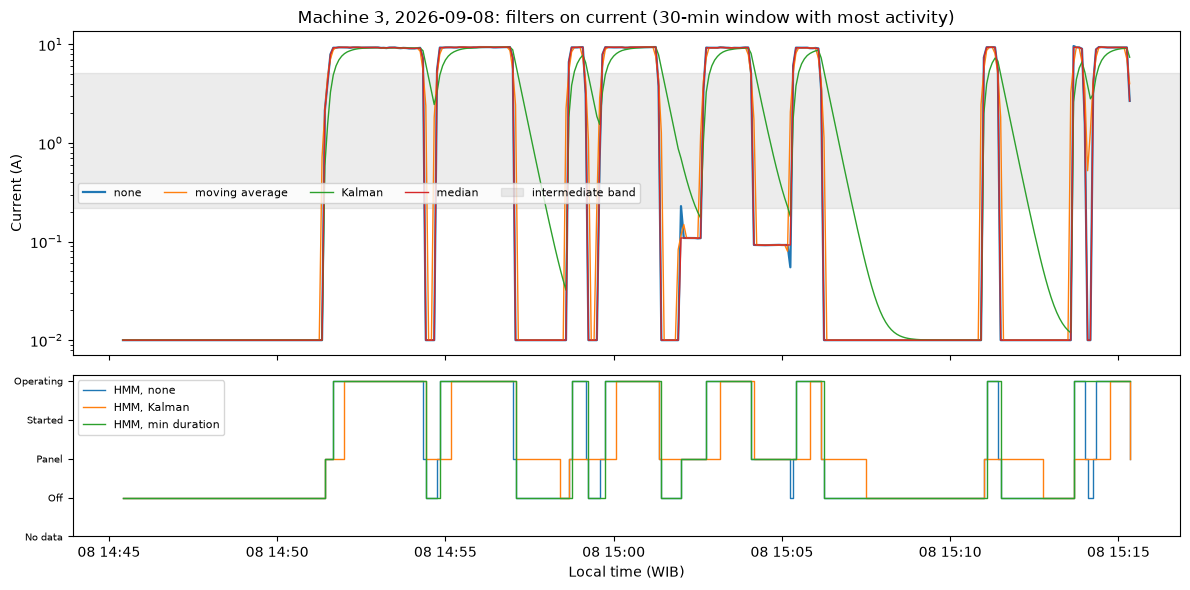

In [6]:
m = (df.day == ZOOM_DAY).to_numpy() & valid
if m.sum() > 360:
    act = pd.Series(np.abs(np.diff(np.log10(I + D.EPS), prepend=0)) * m).rolling(360).sum().to_numpy()
    end = int(np.nanargmax(act)); win = slice(end - 360, end)       # 30 min with the most activity
    t = df.t_local.to_numpy()[win]
    fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
    for k, v in SIG.items():
        ax[0].semilogy(t, v[win] + D.EPS, lw=1.6 if k == "none" else 1, label=k)
    ax[0].axhspan(*band, color="grey", alpha=.15, label="intermediate band")
    ax[0].set_ylabel("Current (A)"); ax[0].legend(fontsize=8, ncol=5)
    ax[0].set_title(f"Machine {MACHINE}, {ZOOM_DAY}: filters on current (30-min window with most activity)")
    for f in ["none", "Kalman", "min duration"]:
        ax[1].step(t, R[("A43 HMM", f)][win], where="post", lw=1, label=f"HMM, {f}")
    ax[1].set_yticks(range(-1, 4), ["No data"] + [STATE[i] for i in range(4)], fontsize=7)
    ax[1].set_xlabel("Local time (WIB)"); ax[1].legend(fontsize=8)
    fig.tight_layout(); fig.savefig(C.FIG / f"m{MACHINE}_filter_zoom.png"); plt.show()
else:
    print("not enough data on", ZOOM_DAY)

## 5 · Summary

In [7]:
h = res.xs("A43 HMM", level="method")
print("HMM by filter (flickers/day | T_op h | cutting h | shift s):")
for f, r in h.iterrows():
    print(f"  {f:15s} {r.flickers_per_day:7.2f} | {r.T_op_h:8.1f} | {r.cutting_h:8.1f} | {r.shift_s}")
best = res.flickers_per_day.idxmin()
print("Fewest flickers:", best, f"({res.loc[best, 'flickers_per_day']:.2f}/day)")

HMM by filter (flickers/day | T_op h | cutting h | shift s):
  none               5.92 |    173.2 |    173.2 | 0.0
  moving average     2.49 |    162.2 |    162.2 | 5.0
  Kalman             0.05 |    149.0 |    149.0 | 20.0
  median             2.64 |    173.0 |    173.0 | 0.0
  min duration       0.02 |    181.2 |    181.2 | 0.0
Fewest flickers: ('A42 GMM', 'min duration') (0.02/day)
